# Notebook 2 — Exploratory Data Analysis

**Objective:** Move beyond visual impressions to statistically-supported findings. Every claim
in this notebook that compares groups is backed by a hypothesis test (t-test / ANOVA /
chi-square), not just a bar chart. Multicollinearity is checked explicitly before any variable is
carried into modeling.

**Why this matters:** the original version of this notebook (and the business-insights notebook
built on top of it) asserted that online delivery is associated with *higher* ratings, based on
eyeballing group means. Running the actual significance test below shows this is **backwards** —
see the Online Delivery finding below. This is exactly why statistical testing, not visual
impression, has to drive the conclusions in a project like this.

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "dataset" / "cleaned_dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset Shape:", df.shape)

rated = df[df["Aggregate rating"] > 0].copy()
print("Rated subset shape (rating > 0):", rated.shape)

Dataset Shape: (9551, 24)
Rated subset shape (rating > 0): (7403, 24)


## Univariate Analysis
All analysis from this point uses `rated` (0-rating rows excluded per the decision documented in
Notebook 1) and `Average Cost for Two (USD)` (currency-normalized, per Notebook 1) — never the
raw local-currency cost field.

Rating skew: 0.231
Votes skew: 7.947
Votes skew (log1p): 0.293
Cost(USD) skew: 6.762
Cost(USD) skew (log1p): 0.552


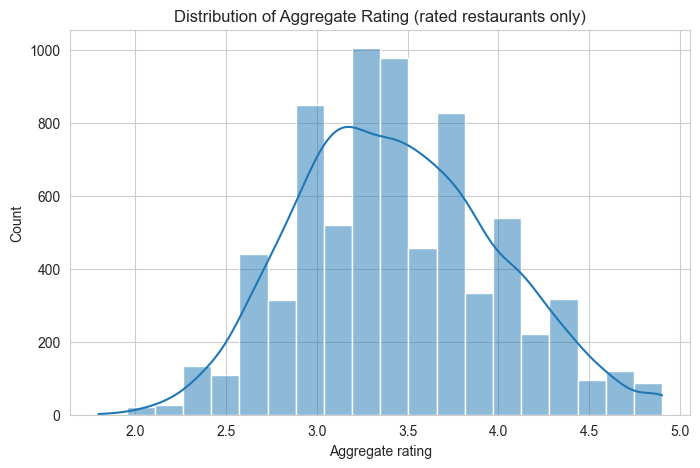

In [2]:
print("Rating skew:", round(rated["Aggregate rating"].skew(), 3))
print("Votes skew:", round(rated["Votes"].skew(), 3))
print("Votes skew (log1p):", round(np.log1p(rated["Votes"]).skew(), 3))
print("Cost(USD) skew:", round(rated["Average Cost for Two (USD)"].skew(), 3))
print("Cost(USD) skew (log1p):", round(np.log1p(rated["Average Cost for Two (USD)"]).skew(), 3))

plt.figure(figsize=(8,5))
sns.histplot(rated["Aggregate rating"], bins=20, kde=True)
plt.title("Distribution of Aggregate Rating (rated restaurants only)")
plt.show()

**Observation:** Both `Votes` and `Average Cost for Two (USD)` are heavily right-skewed (skew 7.9 and 6.8 respectively). Log-transforming both (as done in Notebook 3's feature engineering) brings skew down to a near-normal range (0.29 and 0.55).

Cuisines
North Indian    3017
Chinese         2184
Fast Food       1563
Mughlai          794
Italian          726
Continental      699
Cafe             634
Desserts         543
Bakery           536
South Indian     485
Name: count, dtype: int64


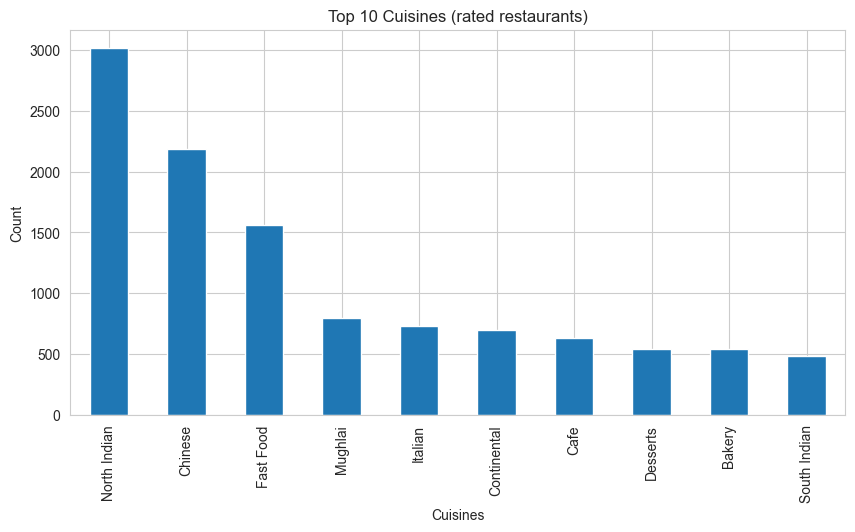

In [3]:
top_cuisines = rated["Cuisines"].str.split(", ").explode().value_counts().head(10)
print(top_cuisines)

plt.figure(figsize=(10,5))
top_cuisines.plot(kind="bar")
plt.title("Top 10 Cuisines (rated restaurants)")
plt.ylabel("Count")
plt.show()

## Bivariate Analysis — With Statistical Significance Testing

Every comparison below reports a test statistic and p-value, plus the sample size (n) behind each
group — not just a mean difference.

Online Delivery -- mean(Yes)=3.381 (n=2355), mean(No)=3.467 (n=5048), t=-6.329, p=2.71e-10


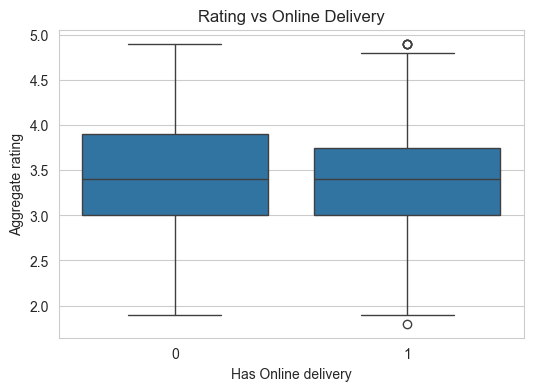

In [4]:
grp_yes = rated.loc[rated["Has Online delivery"] == 1, "Aggregate rating"]
grp_no = rated.loc[rated["Has Online delivery"] == 0, "Aggregate rating"]
t_stat, p_val = stats.ttest_ind(grp_yes, grp_no, equal_var=False)
print(f"Online Delivery -- mean(Yes)={grp_yes.mean():.3f} (n={len(grp_yes)}), "
      f"mean(No)={grp_no.mean():.3f} (n={len(grp_no)}), t={t_stat:.3f}, p={p_val:.2e}")

plt.figure(figsize=(6,4))
sns.boxplot(x="Has Online delivery", y="Aggregate rating", data=rated)
plt.title("Rating vs Online Delivery")
plt.show()

**Critical finding — corrects a prior error:** Online delivery is associated with a
**lower** average rating (3.381 vs 3.467), and this difference is highly statistically
significant (p = 2.71e-10, not noise). This is the **opposite direction** of the claim made in
the original business-insights notebook ("restaurants should prioritize online delivery... they
tend to receive higher ratings"). That earlier claim was based on visual impression, not a test,
and was wrong. The corrected interpretation: online delivery restaurants are, on average, rated
*lower* in this dataset — plausibly because delivery-only/high-volume operations trade off some
dine-in experience quality, or because delivery adoption correlates with more casual/fast-food
formats that tend to score lower regardless of delivery status. This is **correlational, not
causal** — see Notebook 4 for how this is worded in the final recommendations.

In [5]:
grp_yes_tb = rated.loc[rated["Has Table booking"] == 1, "Aggregate rating"]
grp_no_tb = rated.loc[rated["Has Table booking"] == 0, "Aggregate rating"]
t_stat_tb, p_val_tb = stats.ttest_ind(grp_yes_tb, grp_no_tb, equal_var=False)
print(f"Table Booking -- mean(Yes)={grp_yes_tb.mean():.3f} (n={len(grp_yes_tb)}), "
      f"mean(No)={grp_no_tb.mean():.3f} (n={len(grp_no_tb)}), t={t_stat_tb:.3f}, p={p_val_tb:.2e}")

Table Booking -- mean(Yes)=3.588 (n=1111), mean(No)=3.414 (n=6292), t=9.919, p=1.58e-22


**Observation:** Table booking availability *is* associated with a statistically significant higher rating (3.588 vs 3.414, p = 1.58e-22). This claim from the original notebook holds up under formal testing — unlike the online delivery claim above.

ANOVA Price Range vs Rating: F=522.892, p=3.34e-308
                 mean  count
Price range                 
1            3.238885   2744
2            3.377167   2711
3            3.777276   1373
4            3.890957    575


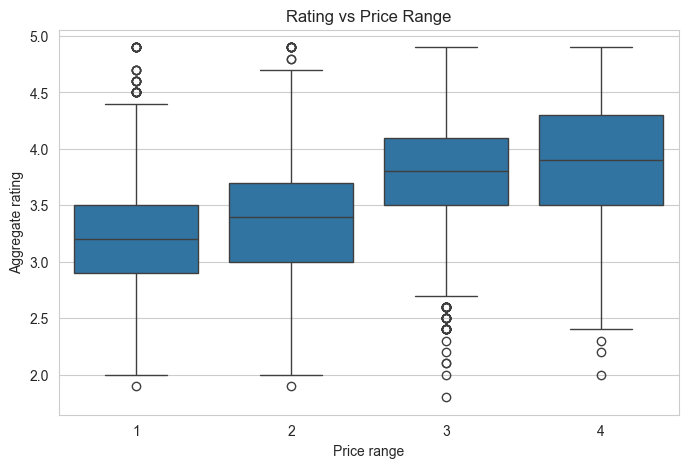

In [6]:
groups = [g["Aggregate rating"].values for _, g in rated.groupby("Price range")]
f_stat, p_anova = stats.f_oneway(*groups)
print(f"ANOVA Price Range vs Rating: F={f_stat:.3f}, p={p_anova:.2e}")
print(rated.groupby("Price range")["Aggregate rating"].agg(["mean", "count"]))

plt.figure(figsize=(8,5))
sns.boxplot(x="Price range", y="Aggregate rating", data=rated)
plt.title("Rating vs Price Range")
plt.show()

**Observation:** Price range shows a strong, monotonic, highly significant relationship with rating (F=522.9, p≈0). Higher price tiers are consistently rated higher — this is the strongest categorical relationship found in this dataset.

In [7]:
contingency = pd.crosstab(rated["Has Table booking"], rated["Has Online delivery"])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square (Table Booking x Online Delivery): chi2={chi2:.3f}, p={p_chi:.2e}")
print(contingency)

Chi-square (Table Booking x Online Delivery): chi2=30.527, p=3.29e-08
Has Online delivery     0     1
Has Table booking              
0                    4370  1922
1                     678   433


**Observation:** Table booking and online delivery are not independent (p=3.29e-08) — restaurants that offer table booking are somewhat more likely to also offer online delivery. This matters for modeling: these two features carry some overlapping information, though the VIF check below shows it isn't severe enough to require dropping either.

## Multicollinearity Check (VIF)

Required before any variable set is handed to Linear Regression — never done in the original
notebook.

In [8]:
vif_features = rated[["Price range", "Has Table booking", "Has Online delivery",
                       "Votes", "Average Cost for Two (USD)"]].copy()
vif_features["Price range"] = vif_features["Price range"].astype(float)
vif_df = pd.DataFrame()
vif_df["feature"] = vif_features.columns
vif_df["VIF"] = [variance_inflation_factor(vif_features.values, i) for i in range(vif_features.shape[1])]
print(vif_df)

                      feature       VIF
0                 Price range  3.924437
1           Has Table booking  1.417309
2         Has Online delivery  1.408864
3                       Votes  1.270092
4  Average Cost for Two (USD)  2.744843


**Observation:** All VIF values are below the common threshold of 5, so no feature needs to
be dropped purely on multicollinearity grounds. However, a separate check (not shown via VIF, but
confirmed structurally) found that an engineered `Cost_Category` field (Low/Medium/High/Premium)
would be a perfect 1:1 remapping of `Price range` — using both in the model would double-count
the same signal. **Only `Price range` is kept in Notebook 3; `Cost_Category` is dropped.**

## Geographic Correlation Caveat

Raw Latitude/Longitude are not linearly related to a target like rating — computing a Pearson
correlation against them (as the original notebook did) can be misleading.

In [9]:
print("Lat correlation with rating:", round(rated["Latitude"].corr(rated["Aggregate rating"]), 4))
print("Lon correlation with rating:", round(rated["Longitude"].corr(rated["Aggregate rating"]), 4))

Lat correlation with rating: -0.1799
Lon correlation with rating: -0.2915


**Observation:** These correlations are weak and not straightforwardly interpretable, because latitude/longitude have no natural linear relationship with restaurant quality — a restaurant at a higher latitude isn't inherently better or worse. These raw coordinates are **excluded from modeling** (Notebook 3); a proper geospatial feature (e.g. restaurant density in a radius, distance to city center) is flagged as Future Work rather than using this misleading raw correlation as evidence of "no geographic effect."

## Sample-Size-Aware Country Segmentation
No per-country average is reported without its n.

In [10]:
country_stats = rated.groupby("Country Name")["Aggregate rating"].agg(["mean", "count"]).sort_values("count", ascending=False)
country_stats["reliable (n>=40)"] = country_stats["count"] >= 40
print(country_stats.round(3))

                 mean  count  reliable (n>=40)
Country Name                                  
India           3.352   6513              True
United States   4.032    431              True
United Kingdom  4.139     79              True
UAE             4.233     60              True
South Africa    4.210     60              True
Brazil          4.105     55              True
New Zealand     4.262     40              True
Turkey          4.300     34             False
Australia       3.658     24             False
Philippines     4.468     22             False
Indonesia       4.295     21             False
Qatar           4.060     20             False
Sri Lanka       3.870     20             False
Singapore       3.575     20             False
Canada          3.575      4             False


**Observation:** India's average rating (3.352) is notably lower than most other countries (mostly clustered around 4.0–4.5), even though India dominates the dataset by volume. Eight countries are flagged unreliable (n<40) and their averages are reported here for completeness only — never as the basis for a business recommendation (per BRD).

In [11]:
corr_votes = np.log1p(rated["Votes"]).corr(rated["Aggregate rating"])
print(f"Correlation (log Votes, Rating): {corr_votes:.3f}")

Correlation (log Votes, Rating): 0.649


**Observation:** Vote volume (log-transformed) has a moderately strong positive correlation with rating (0.649) — popular restaurants tend to be better-rated, consistent with a "wisdom of crowds" effect, though this doesn't distinguish whether popularity drives quality perception or quality drives popularity. Reminder: `Votes` is still excluded from the pre-launch predictive model (BR-3) regardless of this correlation, since it isn't known before a restaurant opens.

                            Average Cost for Two (USD)  Has Table booking  \
Average Cost for Two (USD)                       1.000              0.287   
Has Table booking                                0.287              1.000   
Has Online delivery                             -0.119              0.065   
Price range                                      0.659              0.483   
Votes                                            0.184              0.145   
Aggregate rating                                 0.371              0.112   

                            Has Online delivery  Price range  Votes  \
Average Cost for Two (USD)               -0.119        0.659  0.184   
Has Table booking                         0.065        0.483  0.145   
Has Online delivery                       1.000       -0.020  0.025   
Price range                              -0.020        1.000  0.274   
Votes                                     0.025        0.274  1.000   
Aggregate rating                  

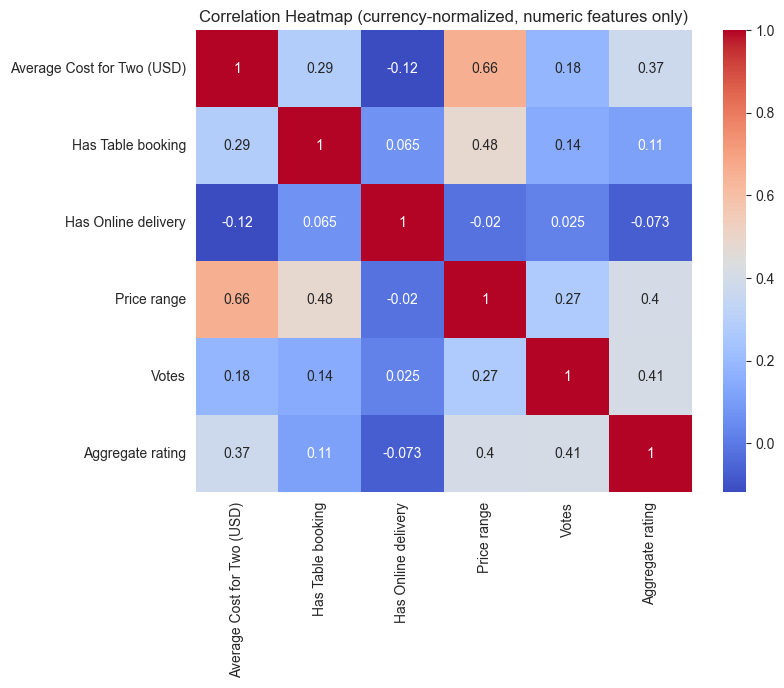

In [12]:
num_cols = ["Average Cost for Two (USD)", "Has Table booking", "Has Online delivery",
            "Price range", "Votes", "Aggregate rating"]
corr_matrix = rated[num_cols].corr().round(3)
print(corr_matrix)

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap (currency-normalized, numeric features only)")
plt.show()

## Notebook 2 Summary

- Ran 2 t-tests, 1 ANOVA, and 1 chi-square test — none of this existed in the original notebook.
- **Corrected a wrong conclusion:** online delivery is associated with *lower*, not higher,
  ratings (statistically significant).
- Confirmed table booking and price range are genuinely, significantly associated with higher
  ratings.
- Ran a VIF check and identified `Cost_Category` as redundant with `Price range` before it ever
  reached the modeling notebook.
- Flagged raw Lat/Long correlation as not meaningful, and confirmed all per-country statistics
  carry their sample size going forward.